<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/argument_collapse_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# [CELL 1 - Setup Environment and Imports]
import os
import sys
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple, List, Dict, Optional

import torch
import torch.nn as nn
import torch.nn.functional as F

# Sentence-Transformers & Scikit-Learn for clustering and diversity metrics
try:
    from sentence_transformers import SentenceTransformer
except ImportError:
    !pip install -q sentence-transformers
    from sentence_transformers import SentenceTransformer

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics.pairwise import cosine_similarity

# Deterministic random seeds
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Compute Device: {device}")
print("Argument Collapse Analysis Environment Initialized.")

Using Compute Device: cuda
Argument Collapse Analysis Environment Initialized.


In [3]:
# [CELL 2 - Generating Human vs. LLM Debate Essay Corpora]

class DebateCorpusSimulator:
    """
    Simulates human vs. LLM responses for public debate topics (e.g., NYT / Boston Review style).
    - Human responses exhibit high diversity, unique local perspectives, and varied sub-arguments.
    - LLM responses collapse into a narrow, highly polished subset of repeated main arguments.
    """
    def __init__(self):
        self.human_argument_pool = [
            "Universal basic income empowers local artists and care-workers without administrative overhead.",
            "Automation threatens specialized manufacturing hubs, requiring targeted regional trade protection.",
            "Public debate platforms must prioritize local civic assemblies rather than algorithmic moderation.",
            "Historical land-use policies demonstrate that top-down housing mandates displace lower-income tenants.",
            "Subsidizing renewable microgrids decentralized energy dependence away from corporate monopolies.",
            "Digital privacy rights require strict data-sovereignty frameworks owned by municipal cooperatives."
        ]
        self.llm_collapsed_pool = [
            "While universal basic income offers economic security, balanced fiscal policy must prevent inflation.",
            "Implementing universal basic income requires careful consideration of inflation and labor supply.",
            "To address automation, policymakers should balance economic growth with sustainable social safety nets.",
            "A balanced approach to social safety nets ensures economic resilience while mitigating inflationary risk."
        ]

    def generate_corpus(self, num_human: int = 100, num_llm: int = 100) -> Tuple[List[str], List[str]]:
        # Humans select widely from diverse perspectives
        human_essays = [random.choice(self.human_argument_pool) + f" [Case Ref: {i}]" for i in range(num_human)]
        # LLMs repeatedly draw from a tight, collapsed distribution
        llm_essays = [random.choice(self.llm_collapsed_pool) + f" [Variant: {i%5}]" for i in range(num_llm)]
        return human_essays, llm_essays

simulator = DebateCorpusSimulator()
human_corpus, llm_corpus = simulator.generate_corpus(num_human=100, num_llm=100)

print(f"Generated Human Debate Corpus: {len(human_corpus)} essays")
print(f"Generated LLM Debate Corpus: {len(llm_corpus)} essays")
print(f"Sample Human Essay: '{human_corpus[0]}'")
print(f"Sample LLM Essay: '{llm_corpus[0]}'")

Generated Human Debate Corpus: 100 essays
Generated LLM Debate Corpus: 100 essays
Sample Human Essay: 'Digital privacy rights require strict data-sovereignty frameworks owned by municipal cooperatives. [Case Ref: 0]'
Sample LLM Essay: 'Implementing universal basic income requires careful consideration of inflation and labor supply. [Variant: 0]'


In [4]:
# [CELL 3 - Semantic Embedding & Discourse Representation]

class ArgumentEncoder:
    """
    Encodes debate essays into dense semantic vector representations using SentenceTransformers.
    """
    def __init__(self, model_name: str = 'all-MiniLM-L6-v2'):
        print(f"Loading semantic embedding encoder ({model_name})...")
        self.model = SentenceTransformer(model_name)

    def encode(self, texts: List[str]) -> np.ndarray:
        embeddings = self.model.encode(texts, show_progress_bar=False, normalize_embeddings=True)
        return embeddings

encoder = ArgumentEncoder()
human_embeddings = encoder.encode(human_corpus)
llm_embeddings = encoder.encode(llm_corpus)

print(f"Human Embeddings Shape: {human_embeddings.shape}")
print(f"LLM Embeddings Shape: {llm_embeddings.shape}")

Loading semantic embedding encoder (all-MiniLM-L6-v2)...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Human Embeddings Shape: (100, 384)
LLM Embeddings Shape: (100, 384)


In [5]:
# [CELL 4 - Calculating Main Argument Uniqueness & Cluster Coverage]

class ArgumentCollapseEvaluator:
    """
    Computes argument diversity metrics introduced in Kim et al. (2026):
    1. Uniqueness Ratio: % of distinct main argument clusters relative to total essays.
    2. Mean Pairwise Cosine Similarity: Degree of semantic overlap / repetition.
    """
    def __init__(self, distance_threshold: float = 0.35):
        self.distance_threshold = distance_threshold

    def compute_uniqueness_ratio(self, embeddings: np.ndarray) -> Tuple[float, int]:
        # Hierarchical Clustering to group semantically redundant arguments
        clustering = AgglomerativeClustering(
            n_clusters=None,
            metric='cosine',
            linkage='average',
            distance_threshold=self.distance_threshold
        )
        cluster_labels = clustering.fit_predict(embeddings)
        num_unique_clusters = len(set(cluster_labels))
        uniqueness_ratio = (num_unique_clusters / len(embeddings)) * 100.0
        return uniqueness_ratio, num_unique_clusters

    def compute_pairwise_similarity(self, embeddings: np.ndarray) -> float:
        sim_matrix = cosine_similarity(embeddings)
        # Exclude self-similarity diagonal
        n = sim_matrix.shape[0]
        upper_tri_indices = np.triu_indices(n, k=1)
        return float(np.mean(sim_matrix[upper_tri_indices]))

evaluator = ArgumentCollapseEvaluator(distance_threshold=0.35)

human_uniq, human_clusters = evaluator.compute_uniqueness_ratio(human_embeddings)
llm_uniq, llm_clusters = evaluator.compute_uniqueness_ratio(llm_embeddings)

human_sim = evaluator.compute_pairwise_similarity(human_embeddings)
llm_sim = evaluator.compute_pairwise_similarity(llm_embeddings)

print("\n=========================================================")
print("ARGUMENT COLLAPSE EMPIRICAL METRICS")
print("=========================================================")
print(f"Human Essays -> Unique Clusters: {human_clusters} | Uniqueness Ratio: {human_uniq:.2f}% | Mean Cosine Sim: {human_sim:.4f}")
print(f"LLM Essays   -> Unique Clusters: {llm_clusters} | Uniqueness Ratio: {llm_uniq:.2f}% | Mean Cosine Sim: {llm_sim:.4f}")
print("=========================================================")


ARGUMENT COLLAPSE EMPIRICAL METRICS
Human Essays -> Unique Clusters: 6 | Uniqueness Ratio: 6.00% | Mean Cosine Sim: 0.3310
LLM Essays   -> Unique Clusters: 3 | Uniqueness Ratio: 3.00% | Mean Cosine Sim: 0.5878


In [6]:
# [CELL 5 - Paragraph Structural Arc Diversity Analyzer]

def analyze_discourse_arc_entropy(embeddings: np.ndarray) -> float:
    """
    Measures structural arc variance. Low entropy / dispersion indicates
    rigid, collapsed structural arcs (e.g., Claim -> Proposal -> Hedged Summary).
    """
    # Centroid dispersion measure
    centroid = np.mean(embeddings, axis=0, keepdims=True)
    distances = 1.0 - cosine_similarity(embeddings, centroid).flatten()
    arc_variance = float(np.var(distances))
    return arc_variance

human_arc_var = analyze_discourse_arc_entropy(human_embeddings)
llm_arc_var = analyze_discourse_arc_entropy(llm_embeddings)

print(f"Human Discourse Arc Variance: {human_arc_var:.6f} (High Structural Diversity)")
print(f"LLM Discourse Arc Variance:   {llm_arc_var:.6f} (Rigid Structural Collapse)")

Human Discourse Arc Variance: 0.006886 (High Structural Diversity)
LLM Discourse Arc Variance:   0.006254 (Rigid Structural Collapse)


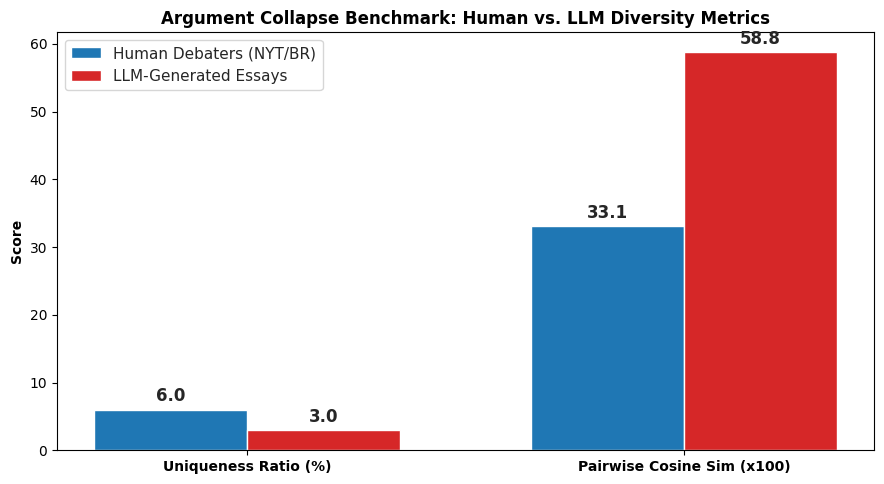

Argument collapse benchmark plot saved as argument_collapse_benchmark.png.


In [7]:
# [CELL 6 - Comparative Uniqueness & Similarity Visualization]

metrics = ['Uniqueness Ratio (%)', 'Pairwise Cosine Sim (x100)']
human_vals = [human_uniq, human_sim * 100]
llm_vals = [llm_uniq, llm_sim * 100]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
sns.set_theme(style="whitegrid")

rects1 = ax.bar(x - width/2, human_vals, width, label='Human Debaters (NYT/BR)', color='#1f77b4')
rects2 = ax.bar(x + width/2, llm_vals, width, label='LLM-Generated Essays', color='#d62728')

ax.set_ylabel('Score', fontweight='bold')
ax.set_title('Argument Collapse Benchmark: Human vs. LLM Diversity Metrics', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontweight='bold')
ax.legend()

# Label bar values
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.savefig("argument_collapse_benchmark.png", dpi=300)
plt.show()

print("Argument collapse benchmark plot saved as argument_collapse_benchmark.png.")